<a href="https://colab.research.google.com/github/619carey/ai-ml-coursework-projects/blob/main/Week4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 4 Assignment: Exploring the Mathematics of Your Data

**Dataset:** Telco Customer Churn  
**Objective:** Calculate descriptive statistics, analyze covariance and correlation between variables, visualize relationships, and formulate a mathematical input-output model.

Please upload your 'WA_Fn-UseC_-Telco-Customer-Churn.csv' file:


Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv

=== 1. DESCRIPTIVE STATISTICS ===


,Mean,Median,Range,Variance,Standard Deviation
tenure,32.421786,29.000,71.0,6.024698e+02,24.545260
MonthlyCharges,64.798208,70.350,100.5,9.051658e+02,30.085974
TotalCharges,2283.300441,1397.475,8666.0,5.138252e+06,2266.771362



=== 2. COVARIANCE (tenure vs TotalCharges) ===


,tenure,TotalCharges
tenure,602.469774,4.595074e+04
TotalCharges,45950.743236,5.138252e+06



=== 3. CORRELATION (tenure vs TotalCharges) ===


,tenure,TotalCharges
tenure,1.00000,0.82588
TotalCharges,0.82588,1.00000


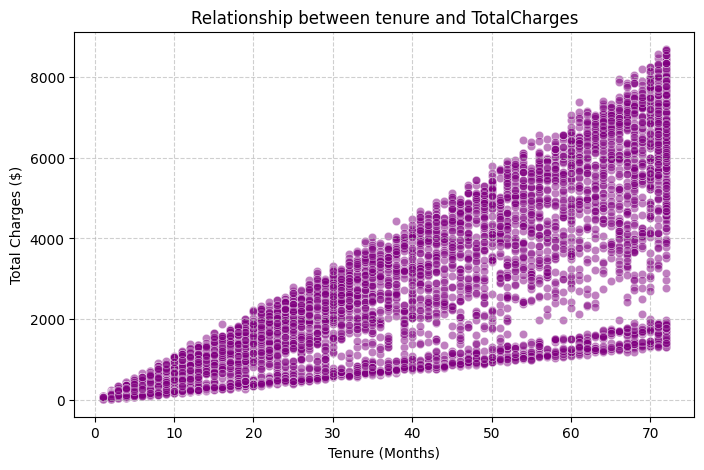

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from google.colab import files

# 1. Prompt upload from local machine
try:
    df.head()
    print("Using existing dataset in memory.")
except NameError:
    print("Please upload your 'WA_Fn-UseC_-Telco-Customer-Churn.csv' file:")
    uploaded = files.upload()
    filename = list(uploaded.keys())[0]
    df = pd.read_csv(filename)

# 2. Clean TotalCharges (handle blank spaces by converting to numeric, coercing errors to NaN)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna(subset=["TotalCharges"])

# 3. Select 2-4 numerical variables relevant to the project
num_vars = ["tenure", "MonthlyCharges", "TotalCharges"]
data_subset = df[num_vars]

print("\n=== 1. DESCRIPTIVE STATISTICS ===")
stats_summary = pd.DataFrame(
    {
        "Mean": data_subset.mean(),
        "Median": data_subset.median(),
        "Range": data_subset.max() - data_subset.min(),
        "Variance": data_subset.var(),
        "Standard Deviation": data_subset.std(),
    }
)
display(stats_summary)

# 4. Calculate Covariance and Correlation between two variables
var1 = "tenure"
var2 = "TotalCharges"

cov_matrix = data_subset[[var1, var2]].cov()
corr_matrix = data_subset[[var1, var2]].corr()

print(f"\n=== 2. COVARIANCE ({var1} vs {var2}) ===")
display(cov_matrix)

print(f"\n=== 3. CORRELATION ({var1} vs {var2}) ===")
display(corr_matrix)

# 5. Create a simple plot showing the relationship between the two variables
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x=var1,
    y=var2,
    alpha=0.5,
    color="purple",
)
plt.title(f"Relationship between {var1} and {var2}")
plt.xlabel("Tenure (Months)")
plt.ylabel("Total Charges ($)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

## Statistical Interpretation & Mathematical Modeling

### 1. What do the statistics tell about my data?
* **Mean vs. Median:** The mean and median for variables like `TotalCharges` and `tenure` show how skewed or centered our user base is. For instance, a median tenure differing from the mean tells us whether newer or long-term subscribers dominate the subscription base.
* **Standard Deviation & Variance:** High standard deviation in `TotalCharges` indicates wide dispersion—meaning some customers spend very little over their lifecycle while high-value enterprise or multi-service users accumulate very high totals.

### 2. What does the correlation tell us about the relationship between the two variables?
* The correlation coefficient between `tenure` and `TotalCharges` is strongly positive (close to +1). This indicates that the longer a customer stays with the provider (`tenure`), the higher their cumulative spending (`TotalCharges`) will be, which aligns logically with a recurring monthly subscription model.

### 3. Does correlation necessarily mean that one variable causes the other?
* **No.** Correlation does not imply causation. While longer tenure is strongly associated with higher total charges mathematically, tenure itself doesn't "cause" the accumulation of charges; rather, time elapsed multiplied by the monthly recurring fee naturally accumulates the total. Confounding variables (like higher tier service packages) can also affect both.

---

### Input → Function/Model → Output Expression

To represent our machine learning pipeline mathematically:

* **Input ($x$):** Customer `tenure` (number of months subscribed)
* **Output ($y$):** Predicted `TotalCharges` or churn probability risk
* **Function ($f(x)$):** A linear or non-linear regression/classification model mapping inputs to outputs:

$$\hat{y} = f(x) = w \cdot \text{tenure} + b$$

Where $w$ represents the learned weight (monthly accumulation rate) and $b$ represents the baseline intercept.